# Del diagnóstico a la decisión

## Planificación multiobjetivo del mantenimiento offshore, con coste, riesgo y fauna del mar del Norte

*Mantenimiento Predictivo para Aerogeneradores Offshore con Restricciones Ambientales. Trabajo de
Fin de Máster. Octavo y último de los notebooks.*

## Resumen

La detección (notebooks 1 a 4) y el diagnóstico (notebook 5) responden *qué* falla y *cómo de
fiable* es la señal. Falta la decisión, **cuándo intervenir**. En un parque *offshore* esa decisión
es un problema de optimización con tres objetivos en conflicto, minimizar el **coste esperado**
(intervención, lucro cesante de la turbina limitada y riesgo de un correctivo catastrófico),
minimizar el **riesgo** de que el componente rompa antes de repararlo, y minimizar el **impacto** de
la operación sobre la fauna del mar del Norte, es decir, el ruido submarino y el tráfico de
embarcaciones en los periodos sensibles. No existe una solución única, sino un **frente de Pareto**
de compromisos.

Este notebook monta ese problema con datos reales. La accesibilidad meteorológica sale de **ERA5**
(German Bight, 2014-2023, horario), y junio es el mes **más accesible** del año, con un 10 % de días
inaccesibles, y a la vez el **pico de reproducción de la marsopa**, que es la tensión central del
sistema. El calendario de especies y los umbrales acústicos vienen de la base
de conocimiento citable del estado de la cuestión. Sobre esa base, el Agente 2 traduce cada alarma
escalada en una tarea, con parámetros tomados de un **catálogo citable** y nunca inventados, NSGA-II
barre el frente, y una regla elige la *rodilla* (*knee*). El modelo de lenguaje solo **narra** el
compromiso.

Se cierra con la pregunta que justifica el sistema entero, **cuánto ahorra el mantenimiento
predictivo**. Mientras la turbina degradada espera la reparación sigue una política **híbrida**, que
limita potencia y para antes de que el riesgo llegue a la certeza. Todo el análisis usa un **único
marco**, el coste esperado del plan del planificador frente a **no hacer nada**.

Agregado por parque sobre **todos** los fallos escalados, con su fecha real, el plan **recomendado**,
que respeta el calendario de fauna, ahorra un **40 %** de la factura reactiva (**51 % en el parque B
y 39 % en el C**, y en lectura de flota, sobre la factura de todas las anomalías, un **29 %**).
**Ignorando la fauna** se llegaría al **56 %**, y esa diferencia, **el 28 % del ahorro ciego**,
concentrada en los fallos de verano que exigen *jack-up* y chocan con el veto de la marsopa, es **lo
que cuesta proteger la fauna**. A cambio, el plan recomendado **reduce un 41 % la perturbación**
sobre las especies, que es el co-beneficio ambiental. Descontando las **falsas alarmas** del triaje
en el mismo marco, el ahorro neto conserva el **76 %**.

Todas las cifras económicas son **relativas**, porque el conjunto de datos está anonimizado, de modo
que lo interpretable es el orden y el porcentaje, no el valor absoluto.

## 0. Preparación y verificación

Se cargan las piezas del sistema, el catálogo de tareas, la base de conocimiento ambiental, el
optimizador y ERA5, y se ejecuta un gate doble. Primero, el frente de NSGA-II **toca el óptimo
exacto** obtenido por fuerza bruta en un sub-caso, con holgura prácticamente nula. Segundo, los
datos ERA5 confirman que **junio es el mes más accesible**, de modo que la tensión del sistema es
real.

In [1]:
# Preparacion del entorno comun a los 4 notebooks XAI
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
for p in (str(ROOT), str(ROOT / "scripts")):
    if p not in sys.path:
        sys.path.insert(0, p)
warnings.filterwarnings("ignore")

# ipykernel OutStream no tiene .buffer: evita que el guard utf-8 de los scripts del repo
# (if sys.stdout.encoding != "utf-8": sys.stdout = io.TextIOWrapper(sys.stdout.buffer, ...))
# intente envolverlo al importarlos.
for _s in (sys.stdout, sys.stderr):
    try:
        if getattr(_s, "encoding", None) != "utf-8":
            _s.encoding = "utf-8"
    except Exception:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.xai import (load_ae, load_ae_events, load_meta, load_scores, load_trajdev,
                     load_trajdev_events, trajdev_channel_z)
from src.xai.loaders import DEVICE, ae_scores, trajdev_forecast_errors, trajdev_score
from src.xai.cusum import cusum_series, first_alarm, h_sweep_best, official_cusum
from src.xai import plots as xp
from src.xai.attrib import (ae_integrated_gradients, ae_residual_sensor, occlusion_per_channel,
                            residual_train_stats, trajdev_counterfactual,
                            trajdev_integrated_gradients)
from src.care_official.adapter import OfficialCAREAdapter

xp.set_style()
np.random.seed(42); torch.manual_seed(42)
print(f"ROOT: {ROOT}")
print(f"dispositivo: {DEVICE} | torch {torch.__version__}")

ROOT: .
dispositivo: cuda | torch 2.10.0+cu128


In [2]:
# Los calculos pesados se cachean en results/xai_cache/nb6/
CACHE = ROOT / "results" / "xai_cache" / "nb6"
CACHE.mkdir(parents=True, exist_ok=True)

def cached(name, fn):
    """np.savez de dict de arrays; si existe, carga sin recomputar."""
    p = CACHE / f"{name}.npz"
    if p.exists():
        z = np.load(p, allow_pickle=True)
        return {k: z[k] for k in z.files}
    out = fn()
    np.savez_compressed(p, **out)
    return out

print(f"cache: {CACHE}")

cache: .\results\xai_cache\nb6


In [3]:
from datetime import date, timedelta

from src.agents.contracts import (AlarmReport, TriageAction, MaintenanceTask, PlanRequest, VetoDuro)
from src.agents.diagnose import DiagnoseAgent
from src.agents.plan import PlannerAgent, _fmt_sched, MESES
from src.agents.tools.xai_tools import get_alarm_evidence
from src.agents.tools.solver_tools import solve_plan
from src.agents.tools.catalog_tools import load_catalog, catalog_task, subsistemas_catalogo
from src.agents.tools.env_tools import load_kb, sensibilidad_dia, veto_jackup_periodo_sensible
from src.scheduler.scenarios import Era5Provider

_req_gate = PlanRequest(
    t0=date(2026, 6, 1), horizonte_dias=60,
    tasks=[catalog_task("multiplicadora", "G1", "C", 1, ventana_fin_dia=40),
           catalog_task("generador", "G2", "C", 2, ventana_fin_dia=40)],
    periodos_ambientales=load_kb()[0], vetos_duros=veto_jackup_periodo_sensible(),
    n_escenarios_meteo=20, weather_provider="era5", seed=42)
_front_gate = solve_plan(_req_gate)
_gap = _front_gate.validacion_exacta.gap
assert _front_gate.validacion_exacta.optimo_alcanzado, f"NSGA no toca el optimo exacto (gap {_gap})"

_inacc = Era5Provider().monthly_inaccessibility()
_min_mes = int(np.argmin(_inacc)) + 1
assert _min_mes == 6, f"el mes mas accesible en ERA5 no es junio: {_min_mes}"
print(f"GATE OK — NSGA-II toca el optimo exacto (gap {_gap:.4f}); ERA5: junio = mes mas accesible "
      f"({_inacc[5]:.0f}% inaccesible), pico reproduccion marsopa. {len(_front_gate.soluciones)} sols en el sub-frente.")

GATE OK — NSGA-II toca el optimo exacto (gap 0.0000); ERA5: junio = mes mas accesible (10% inaccesible), pico reproduccion marsopa. 300 sols en el sub-frente.


## 1. La mejor meteorología cae en el peor momento para la fauna

El mantenimiento *offshore* vive condicionado por las **ventanas meteorológicas**, porque una
embarcación solo puede operar si la altura de ola y el viento están por debajo de umbral. Con datos
ERA5 reales del German Bight (2014-2023, ola y viento horarios, con accesibilidad definida como al
menos 8 h al día con Hs < 1.5 m y viento < 12 m/s), la estacionalidad es nítida y el verano es la
temporada de trabajo.

El problema es que ese mismo verano es el periodo más sensible para la fauna del mar del Norte, con
la **reproducción de la marsopa** (mayo-agosto, con zona de cría en el área protegida del Sylt Outer
Reef), la **alimentación del rorcual aliblanco** (junio-octubre, un cetáceo de baja frecuencia
sensible al ruido por debajo de 1 kHz), la **paridera de la foca común** en el mar de Frisia (junio)
y la **nidificación de aves marinas** (abril-julio), perturbadas por el tráfico. La base de
conocimiento recoge también una ventana **invernal**, la paridera de la foca gris entre noviembre y
enero, que la meteorología rara vez permite trabajar. La figura confronta accesibilidad y
sensibilidad.

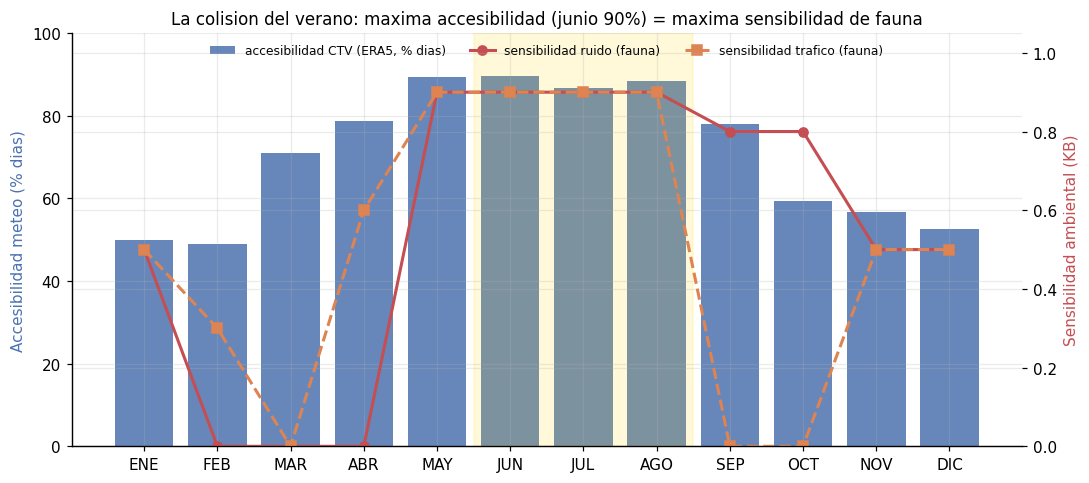

Junio: accesibilidad 90% (maxima) y sensibilidad ruido 0.9 (maxima, marsopa).
Octubre: accesibilidad 59% y sensibilidad ruido 0.8 (rorcual, sin marsopa).


In [4]:
inacc = Era5Provider().monthly_inaccessibility()
periodos = load_kb()[0]
sens_traf = np.array([sensibilidad_dia(date(2026, m, 15), "trafico_embarcaciones", periodos) for m in range(1, 13)])
sens_ruido = np.array([sensibilidad_dia(date(2026, m, 15), "ruido_operacional", periodos) for m in range(1, 13)])
acc = 100 - inacc  # accesibilidad %

fig, ax1 = plt.subplots(figsize=(10, 4.5))
x = np.arange(12)
ax1.bar(x, acc, color="#4C72B0", alpha=0.85, label="accesibilidad CTV (ERA5, % dias)")
ax1.set_ylabel("Accesibilidad meteo (% dias)", color="#4C72B0")
ax1.set_xticks(x); ax1.set_xticklabels([m.upper() for m in MESES])
ax1.set_ylim(0, 100)
ax2 = ax1.twinx()
ax2.plot(x, sens_ruido, "o-", color="#C44E52", lw=2, label="sensibilidad ruido (fauna)")
ax2.plot(x, sens_traf, "s--", color="#DD8452", lw=2, label="sensibilidad trafico (fauna)")
ax2.set_ylabel("Sensibilidad ambiental (KB)", color="#C44E52"); ax2.set_ylim(0, 1.05)
ax1.axvspan(4.5, 7.5, color="gold", alpha=0.15)
ax1.set_title("La colision del verano: maxima accesibilidad (junio 90%) = maxima sensibilidad de fauna")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

print(f"Junio: accesibilidad {acc[5]:.0f}% (maxima) y sensibilidad ruido {sens_ruido[5]:.1f} (maxima, marsopa).")
print(f"Octubre: accesibilidad {acc[9]:.0f}% y sensibilidad ruido {sens_ruido[9]:.1f} (rorcual, sin marsopa).")

### 1.1 ¿Depende esta tensión de los pesos que elegimos?

Los pesos de sensibilidad de la base de conocimiento (marsopa 0.9, rorcual 0.8, foca común 0.7, aves
0.6, foca gris 0.5) son un supuesto de modelado, y la objeción es legítima. ¿Depende la conclusión
de esos números? El análisis de sensibilidad (`scripts/agentes/env_sensitivity.py`) los perturba de todas
las formas, con esquemas fijos, inversión completa del orden y doscientas perturbaciones aleatorias
de ±30 %, y mide el impacto de una misma intervención según el mes.

Lo **robusto** es que **junio perturba más que octubre en 200 de 200 perturbaciones**, elijas los
pesos que elijas, porque en verano se solapan varias especies. Con un matiz que conviene declarar,
el **pico absoluto** del año no siempre cae en verano, porque al aplanar los pesos la ventana
invernal de la foca gris puede igualarlo, pero es irrelevante para planificar, ya que el invierno es
justamente el periodo **menos** accesible. La tensión operativa, la de ser accesible **y** sensible
a la vez, vive en verano.

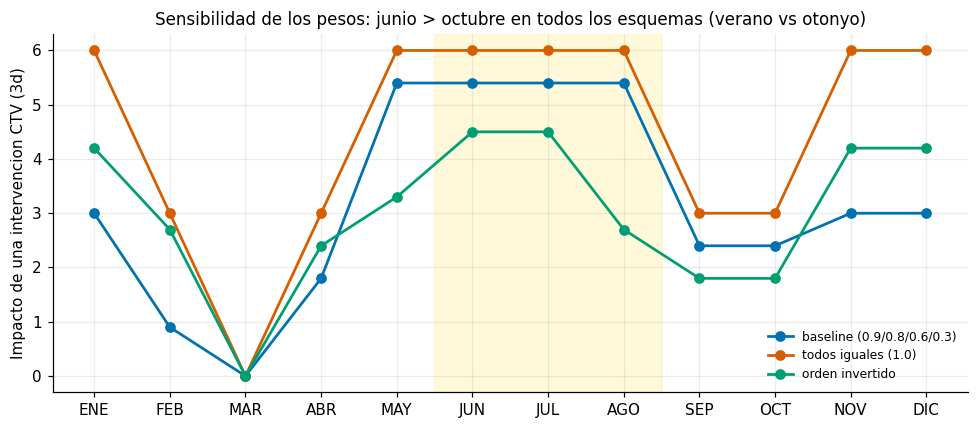

Perturbaciones aleatorias +-30% (n=200): junio > octubre en 200/200 (ROBUSTO).


In [5]:
def curva_impacto(pers):
    out = []
    for m in range(1, 13):
        dias = [date(2026, m, 15) + timedelta(days=d) for d in range(3)]
        out.append(sum(sensibilidad_dia(d, "trafico_embarcaciones", pers)
                       + sensibilidad_dia(d, "ruido_operacional", pers) for d in dias))
    return np.array(out)

def perturbar(pers, fn):
    return [p.model_copy(update={"sensibilidad": float(np.clip(fn(p), 0, 1))}) for p in pers]

esquemas = {
    "baseline (0.9/0.8/0.6/0.3)": periodos,
    "todos iguales (1.0)": perturbar(periodos, lambda p: 1.0),
    "orden invertido": perturbar(periodos, lambda p: {0.9: 0.3, 0.8: 0.6, 0.6: 0.8, 0.3: 0.9}.get(p.sensibilidad, p.sensibilidad)),
}
plt.figure(figsize=(9, 4))
for name, per in esquemas.items():
    plt.plot(np.arange(12), curva_impacto(per), "o-", lw=1.8, label=name)
plt.axvspan(4.5, 7.5, color="gold", alpha=0.15)
plt.xticks(np.arange(12), [m.upper() for m in MESES]); plt.ylabel("Impacto de una intervencion CTV (3d)")
plt.title("Sensibilidad de los pesos: junio > octubre en todos los esquemas (verano vs otonyo)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

rng = np.random.default_rng(42)
jun_gt_oct = 0
for _ in range(200):
    c = curva_impacto(perturbar(periodos, lambda p: p.sensibilidad * (1 + rng.uniform(-.3, .3))))
    jun_gt_oct += int(c[5] > c[9])
print(f"Perturbaciones aleatorias +-30% (n=200): junio > octubre en {jun_gt_oct}/200 (ROBUSTO).")

## 2. Del diagnóstico al plan, el Agente 2

El Agente 1 (notebook 5) entrega, por cada alarma, un **AlarmReport** con su categorización. Solo
los `escalar`, que son la salida fiable y robusta a la semilla, se convierten en tareas. El Agente 2
hace la **traducción**, es decir, elige el subsistema y toma sus parámetros, la duración, el coste
de intervención, el riesgo, el coste correctivo y si necesita buque autoelevable (*jack-up*), de un
**catálogo citable** (`src/scheduler/kb/tareas.yaml`), con su fuente y su marca de supuesto por
entrada.

**El modelo de lenguaje nunca escribe números.** Como en el Agente 1, las reglas deciden y el modelo
solo redacta. Se diagnostican a continuación dos alarmas reales del *benchmark*.

In [6]:
diag = DiagnoseAgent(llm=None)   # sin LLM -> diagnostico determinista (reproducible)
CASOS = [("C", 11), ("B", 53)]   # relacional fuerte (jack-up) + mixto (CTV)
reports = []
for farm, ev in CASOS:
    rep = diag.run(get_alarm_evidence(farm, ev))
    reports.append(rep)
    e = rep.evidencia
    print(f"{farm} ev{ev}: margen {e.margen_sh:7.2f} | {rep.tipo_precursor.value:12s} "
          f"-> {rep.triage.action.value.upper()} (urg {rep.urgencia_dias}d)")

cat = load_catalog()
print("\nCatalogo de subsistemas (costes relativos):")
for k in subsistemas_catalogo():
    s = cat["subsistemas"][k]
    print(f"  {k:20s} dur {s['duracion_dias']}d  interv {s['coste_intervencion']:>8,.0f}  "
          f"correctivo {s['coste_correctivo']:>8,.0f}  {'JACK-UP' if s['requiere_jackup'] else 'CTV'}")

C ev11: margen  600.34 | relacional   -> ESCALAR (urg 28d)


B ev53: margen   35.44 | mixto        -> ESCALAR (urg 30d)

Catalogo de subsistemas (costes relativos):
  multiplicadora       dur 5d  interv  250,000  correctivo  800,000  JACK-UP
  rodamiento_principal dur 4d  interv  180,000  correctivo  500,000  JACK-UP
  generador            dur 3d  interv  120,000  correctivo  400,000  CTV
  pitch                dur 1d  interv   15,000  correctivo   80,000  CTV
  convertidor          dur 1d  interv   25,000  correctivo  120,000  CTV
  generico             dur 2d  interv   60,000  correctivo  250,000  CTV


### 2.1 El frente de Pareto de una campaña

Se planifican las dos intervenciones juntas, como una campaña de parque, empezando en **octubre** y
con las restricciones ambientales activas. NSGA-II barre el frente y cada punto es un calendario
distinto. La regla del *knee*, el punto más cercano al ideal en el espacio normalizado, elige el
compromiso, y el `greedy` de referencia, que interviene lo antes posible e ignora la fauna, es el
punto de comparación.

Mientras espera la reparación, la turbina degradada sigue la política **híbrida**, es decir,
**limita potencia** mientras el riesgo es tolerable y, si la reparación se difiere tanto que el
riesgo alcanzaría el umbral de seguridad (`RIESGO_STOP`), **para** hasta repararla. Así el riesgo
queda **acotado** y diferir de más se penaliza con la producción perdida durante la parada. El
optimizador solo elige *cuándo reparar*, porque la parada de seguridad es una regla y no una
variable de decisión.

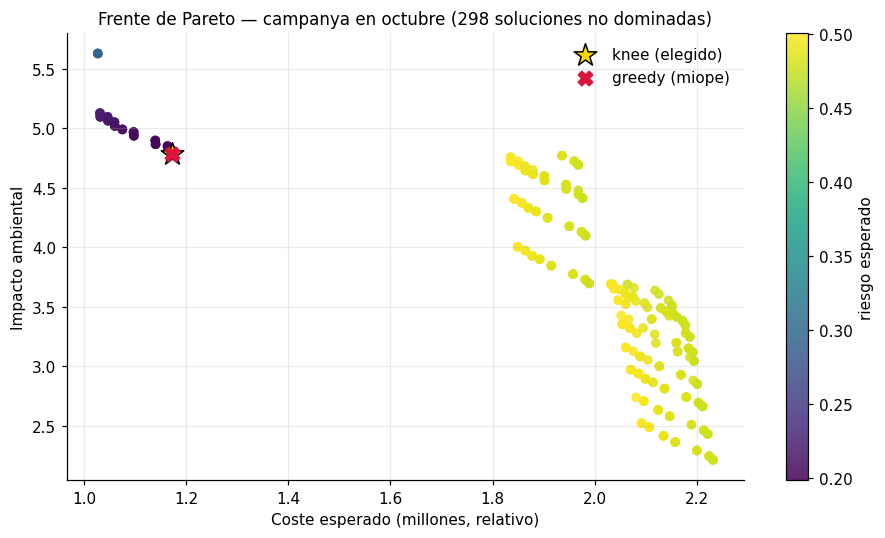

PLAN ELEGIDO (knee): C-ev11@d0 (oct), B-ev53@d0 (oct)
  coste 1,171,576 | riesgo 0.20 | impacto 4.8

Narrativa (determinista; con Ollama la redacta qwen3 citando estos mismos numeros):
  Recomendacion: intervenir en [C-ev11@d0 (oct), B-ev53@d0 (oct)].
Por que: equilibra coste, riesgo e impacto ambiental; respeta el veto de reproduccion Marsopa comun (sensibilidad 0.9, KB).
A que atenerse: coste esperado 1,171,576 (riesgo 0.20, impacto 4.8); ~145,058 mas que la opcion mas barata del frente, a cambio de menor impacto y/o riesgo.


In [7]:
planner = PlannerAgent(llm=None)
req_oct = planner.build_request(reports, date(2026, 10, 1), 180, con_restricciones=True,
                               weather_provider="era5", n_escenarios=40, politica="hibrida")
front_oct = solve_plan(req_oct)
plan_oct = planner.explain(front_oct, req_oct, reports, escenario_desc="octubre, con restricciones")

F = np.array([[s.objetivos.coste_esperado, s.objetivos.riesgo_esperado, s.objetivos.impacto_ambiental]
              for s in front_oct.soluciones])
knee = front_oct.knee_idx
g = front_oct.baseline_greedy.objetivos

fig, ax = plt.subplots(figsize=(8.5, 5))
sc = ax.scatter(F[:, 0] / 1e6, F[:, 2], c=F[:, 1], cmap="viridis", s=28, alpha=0.85)
ax.scatter(F[knee, 0] / 1e6, F[knee, 2], s=240, marker="*", edgecolor="k", facecolor="gold",
           zorder=5, label="knee (elegido)")
ax.scatter(g.coste_esperado / 1e6, g.impacto_ambiental, s=90, marker="X", color="crimson",
           zorder=5, label="greedy (miope)")
plt.colorbar(sc, label="riesgo esperado")
ax.set_xlabel("Coste esperado (millones, relativo)"); ax.set_ylabel("Impacto ambiental")
ax.set_title(f"Frente de Pareto — campanya en octubre ({len(F)} soluciones no dominadas)")
ax.legend(); plt.tight_layout(); plt.show()

print("PLAN ELEGIDO (knee):", _fmt_sched(plan_oct.elegido, req_oct))
print(f"  coste {plan_oct.elegido.objetivos.coste_esperado:,.0f} | riesgo {plan_oct.elegido.objetivos.riesgo_esperado:.2f} "
      f"| impacto {plan_oct.elegido.objetivos.impacto_ambiental:.1f}")
print("\nNarrativa (determinista; con Ollama la redacta qwen3 citando estos mismos numeros):")
print(" ", plan_oct.narrativa)

## 3. Análisis de sensibilidad estacional, junio frente a octubre

**Atención.** Los fallos reales se reparten por todo el año, el verano aporta en
torno al 30 % de forma proporcional, la alarma de C ev11 es de octubre y la de B ev53 de diciembre.
Esto **no** supone que ocurran en verano.

Lo que sigue es un análisis de *sensibilidad*, en el que se resuelve la **misma** campaña como si la
alarma llegara en **junio** en lugar de en **octubre**, para aislar el efecto de la estación. La
diferencia no es un matiz. En junio la intervención de multiplicadora necesita *jack-up*, y el
**veto de reproducción de la marsopa** (mayo-agosto, derivado de la base de conocimiento) prohíbe
movilizarlo, de modo que hay que diferir a otoño con el coste que eso acarrea.

In [8]:
req_jun = planner.build_request(reports, date(2026, 6, 1), 180, con_restricciones=True,
                               weather_provider="era5", n_escenarios=40, politica="hibrida")
front_jun = solve_plan(req_jun)
plan_jun = planner.explain(front_jun, req_jun, reports, escenario_desc="junio, con restricciones")

for lbl, req, plan, front in [("JUNIO ", req_jun, plan_jun, front_jun), ("OCTUBRE", req_oct, plan_oct, front_oct)]:
    o = plan.elegido.objetivos
    print(f"{lbl}: [{_fmt_sched(plan.elegido, req)}]  coste {o.coste_esperado:>11,.0f}  "
          f"riesgo {o.riesgo_esperado:.2f}  impacto {o.impacto_ambiental:.1f}  ({len(front.soluciones)} sols)")

print("\n¿Y si...? (narrativa comparativa):")
print(" ", planner.comparar_escenarios(("junio+restr", req_jun, front_jun, plan_jun),
                                        ("octubre+restr", req_oct, front_oct, plan_oct)))
print("\nEl veto derivado de la KB:", req_jun.vetos_duros[0].motivo)

JUNIO : [C-ev11@d92 (sep), B-ev53@d3 (jun)]  coste   1,594,050  riesgo 0.48  impacto 8.2  (24 sols)
OCTUBRE: [C-ev11@d0 (oct), B-ev53@d0 (oct)]  coste   1,171,576  riesgo 0.20  impacto 4.8  (298 sols)

¿Y si...? (narrativa comparativa):
  Comparativa junio+restr vs octubre+restr: el impacto ambiental pasa de 8.2 a 4.8 y el coste de 1,594,050 a 1,171,576.

El veto derivado de la KB: reproduccion Marsopa comun (sensibilidad 0.9, KB)


## 4. Afinar la espera, optimizar también cuándo parar

Hasta aquí la turbina degradada seguía la híbrida de **umbral fijo**, que limita potencia y para en
cuanto el riesgo alcanza el umbral de seguridad (`RIESGO_STOP`). Eso es un límite de seguridad, no
una decisión. Pero el día de parada es en sí mismo un compromiso, porque parar **antes** pierde
producción, pero **congela el riesgo** antes y **corta el ruido continuo** de la máquina degradada
en las ventanas sensibles.

La **híbrida optimizada** (`hibrida_opt`) convierte ese día de parada en una **segunda variable de
decisión** por tarea, **acotada por el umbral de seguridad**. El optimizador puede parar antes, para
bajar riesgo o impacto, pero nunca después, de modo que el límite de seguridad se conserva intacto.
Ya no elige solo *cuándo reparar*, sino también *cuándo dejar de operar*. Se comparan ambas sobre la
misma campaña de octubre, con fauna.

In [9]:
# optimizar TAMBIEN el dia de parada, acotado por el umbral de seguridad
req_oct_opt = planner.build_request(reports, date(2026, 10, 1), 180, con_restricciones=True,
                                   weather_provider="era5", n_escenarios=40, politica="hibrida_opt")
front_oct_opt = solve_plan(req_oct_opt)
k_fix = front_oct.soluciones[front_oct.knee_idx]           # hibrida umbral FIJO
k_opt = front_oct_opt.soluciones[front_oct_opt.knee_idx]   # parada OPTIMIZADA

print("Knee de la misma campanya de octubre (con fauna), por politica de espera:")
for lbl, k in [("hibrida (parada FIJA en el umbral)", k_fix), ("hibrida_opt (parada OPTIMIZADA)", k_opt)]:
    o = k.objetivos
    par = [s.dia_parada for s in k.schedule]
    extra = f"  paradas(dia) {par}" if any(p is not None for p in par) else ""
    print(f"  {lbl:34s} coste {o.coste_esperado:>11,.0f}  riesgo {o.riesgo_esperado:.3f}  "
          f"impacto {o.impacto_ambiental:4.1f}{extra}")

of, oo = k_fix.objetivos, k_opt.objetivos
print(f"\nOptimizar la parada mueve coste {oo.coste_esperado-of.coste_esperado:+,.0f}, "
      f"riesgo {of.riesgo_esperado:.3f}->{oo.riesgo_esperado:.3f}, "
      f"impacto {of.impacto_ambiental:.1f}->{oo.impacto_ambiental:.1f}.")

Knee de la misma campanya de octubre (con fauna), por politica de espera:
  hibrida (parada FIJA en el umbral) coste   1,171,576  riesgo 0.199  impacto  4.8
  hibrida_opt (parada OPTIMIZADA)    coste   2,133,932  riesgo 0.181  impacto  0.8  paradas(dia) [1, 1]

Optimizar la parada mueve coste +962,355, riesgo 0.199->0.181, impacto 4.8->0.8.


## 5. Cuánto ahorra el predictivo, por parque y sobre todos los fallos

La campaña anterior era ilustrativa, con dos alarmas. La pregunta que justifica el sistema se
responde sobre el **agregado**, es decir, cuánto ahorra el mantenimiento predictivo en **cada
parque**, sumando **todos** sus fallos detectados y escalados, con la **fecha real** de cada uno.
Esto importa porque los fallos se reparten por todo el año, en B de febrero a diciembre y en C once
de los doce meses, y la fauna es estacional, de modo que un *jack-up* de **verano** choca con el
veto de la marsopa y es caro de planificar, mientras que uno de **invierno** no.

Para cada fallo escalado se planifica su intervención en su mes real y se recomienda el mejor plan
de entre **todas las políticas de espera** del menú, que son limitar potencia, limitar y parar, o
parar del todo. Es la misma definición `recomendar_union` que usa la consola de operador, en la que
se toma el *knee* de cada política, es decir, su plan representativo, y entre ellos se elige el
**más barato**, descartando los que pierden la turbina, con riesgo próximo a 1, y los de impacto
elevado. Así la parada solo se recomienda cuando de verdad es la más barata, por ejemplo con un
*jack-up* vetado en verano, y no solo por bajar el impacto a costa del dinero.

Se comparan, frente a **no hacer nada** (dejar correr cada fallo hasta la rotura), el plan
**recomendado**, que respeta el calendario de fauna, y el **ciego a la fauna**, que elige siempre el
mínimo coste. Su diferencia es **lo que cuesta proteger la fauna**.

Se dan **dos lecturas del porcentaje**, y se muestran las dos para no exagerar ninguna:

1. Sobre la factura reactiva de los fallos que el sistema **captura**, que es la de las barras.
2. **Sobre la flota**, es decir, sobre la factura de **todas** las anomalías del parque, incluidas
   las que el triaje no escala.

El ahorro **en euros es el mismo** en ambas. El porcentaje de la segunda es menor porque un fallo no
capturado corre a rotura con o sin sistema, de modo que no es un coste añadido sino **ahorro no
capturado**, es decir, el límite de cobertura de la detección, que se mide en CARE en los notebooks
1 a 4 y aquí se expresa en moneda.

In [10]:
from src.agents.tools.xai_tools import _context
from src.agents.plan import _SUBSISTEMA_POR_TIPO, recursos_catalogo
from src.scheduler.nsga2 import solve_nsga2
from src.scheduler.problem import SchedulingProblem
from src.scheduler.savings import coste_reactivo_tarea, recomendar_union, POLITICAS_MENU
_cat = load_catalog()["subsistemas"]
_diag = DiagnoseAgent()   # sin LLM

# triaje sobre TODOS los eventos de ambas granjas
TRIAJE = {}
for _f in ["B", "C"]:
    _meta = _context(_f)["meta"]
    _lst = []
    for _e in sorted(_meta):
        _rep = _diag.run(get_alarm_evidence(_f, _e))
        _sub = _SUBSISTEMA_POR_TIPO.get(_rep.tipo_precursor, "generico")
        _lst.append(dict(ev=_e, label=_meta[_e]["event_label"], action=_rep.triage.action,
                         sub=(_sub if _sub in _cat else "generico"),
                         mes=_meta[_e]["window_timestamps"][0].month))
    TRIAJE[_f] = _lst

# plan RECOMENDADO por (subsistema, mes), con y sin fauna
HORIZ, NESC = 270, 20
_memo = {}
def _plan_rec(sub, mes, con_fauna):
    key = (sub, mes, con_fauna)
    if key not in _memo:
        task = catalog_task(sub, "T", "C", 0, ventana_fin_dia=HORIZ - 1)
        per = load_kb()[0] if con_fauna else []
        vet = veto_jackup_periodo_sensible(per) if con_fauna else []
        per_pol = []
        for pol in POLITICAS_MENU:
            req = PlanRequest(t0=date(2026, mes, 1), horizonte_dias=HORIZ, tasks=[task],
                              recursos=recursos_catalogo(), n_escenarios_meteo=NESC, weather_provider="era5",
                              seed=42, periodos_ambientales=per, vetos_duros=vet, politica_espera=pol)
            per_pol.append(solve_nsga2(req, pop_size=60, n_gen=80, n_seeds=2,
                                       prob=SchedulingProblem.from_request(req)).soluciones)
        react = coste_reactivo_tarea(task)
        if con_fauna:
            # RECOMENDADO = recomendar_union (precio-primero entre knees de politica, sin turbina-perdida ni impacto elevado, respetando el veto/periodos)
            sols, idx, _F, _pol, react = recomendar_union(per_pol, [task])
            rec = sols[idx]
        else:
            # CIEGO (ignora la fauna) = minimo coste ABSOLUTO, sin filtro de impacto (un operador que no mira la fauna tampoco mira el impacto)
            _todos = [s for lst in per_pol for s in lst if s.objetivos.riesgo_esperado < 0.95]
            rec = min(_todos, key=lambda s: s.objetivos.coste_esperado)
        _memo[key] = (react, rec)
    return _memo[key]

# impacto REAL de un plan (su dia de inicio) con la fauna activa y SIN veto
def _impacto_real(sub, mes, dia_inicio):
    task = catalog_task(sub, "T", "C", 0, ventana_fin_dia=HORIZ - 1)
    req = PlanRequest(t0=date(2026, mes, 1), horizonte_dias=HORIZ, tasks=[task], recursos=recursos_catalogo(),
                      n_escenarios_meteo=NESC, weather_provider="era5", seed=42,
                      periodos_ambientales=load_kb()[0], vetos_duros=[], politica_espera="hibrida_opt")
    return SchedulingProblem.from_request(req).evaluate_plan([dia_inicio]).impacto_ambiental

# agregado POR GRANJA sobre los FALLOS (anomalias) detectados y escalados
AGG = {}
for _f in ["B", "C"]:
    _esc = [d for d in TRIAJE[_f] if d["action"] is TriageAction.ESCALAR and d["label"] == "anomaly"]
    _re = _rc = _rs = _ir = _ib = 0.0
    for d in _esc:
        react, rec_con = _plan_rec(d["sub"], d["mes"], True)
        _, rec_sin = _plan_rec(d["sub"], d["mes"], False)
        _re += react
        _rc += rec_con.objetivos.coste_esperado
        _rs += rec_sin.objetivos.coste_esperado
        _ir += rec_con.objetivos.impacto_ambiental                                # impacto del plan que RESPETA la fauna
        _ib += _impacto_real(d["sub"], d["mes"], rec_sin.schedule[0].dia_inicio)   # impacto REAL del plan CIEGO
    AGG[_f] = dict(n=len(_esc), reactivo=_re, recomendado=_rc, sin_fauna=_rs, imp_rec=_ir, imp_ciego=_ib)
AGG["Total"] = {k: sum(AGG[f][k] for f in ["B", "C"]) for k in AGG["B"]}

for k in ["B", "C", "Total"]:
    a = AGG[k]; ar = a["reactivo"] - a["recomendado"]; asf = a["reactivo"] - a["sin_fauna"]
    et = f"Farm {k}" if k != "Total" else "TOTAL B+C"
    print(f"{et:9s} ({a['n']:2d} fallos escalados) | reactivo {a['reactivo']:>12,.0f} | "
          f"recomendado(fauna) {a['recomendado']:>12,.0f} (ahorro {ar:>11,.0f}, {100*ar/a['reactivo']:.0f}%) | "
          f"sin fauna {a['sin_fauna']:>12,.0f} (ahorro {asf:>11,.0f}, {100*asf/a['reactivo']:.0f}%)")

Farm B    ( 4 fallos escalados) | reactivo    2,969,600 | recomendado(fauna)    1,462,016 (ahorro   1,507,584, 51%) | sin fauna    1,216,541 (ahorro   1,753,059, 59%)
Farm C    (17 fallos escalados) | reactivo   18,691,200 | recomendado(fauna)   11,493,433 (ahorro   7,197,767, 39%) | sin fauna    8,326,144 (ahorro  10,365,056, 55%)
TOTAL B+C (21 fallos escalados) | reactivo   21,660,800 | recomendado(fauna)   12,955,448 (ahorro   8,705,352, 40%) | sin fauna    9,542,686 (ahorro  12,118,114, 56%)


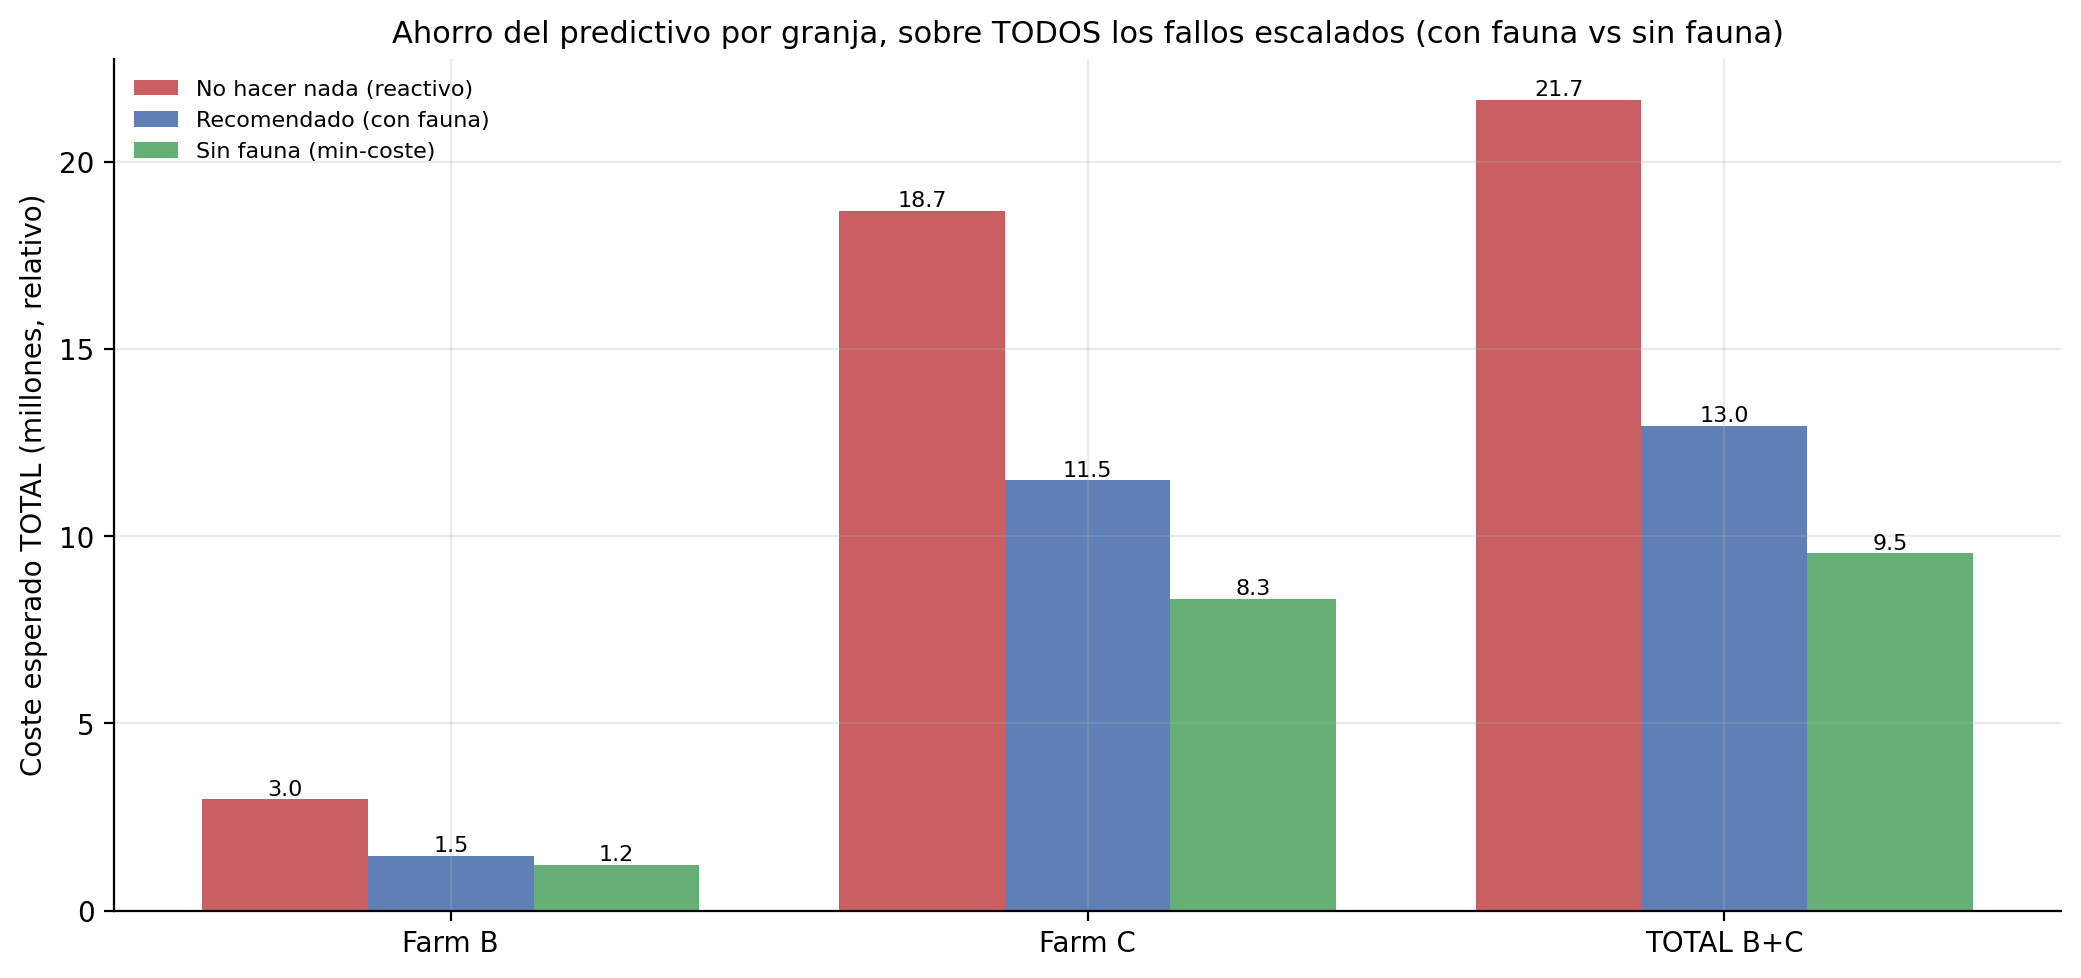

TOTAL B+C sobre 21 fallos escalados (coste relativo):
  (1) ahorro sobre NO HACER NADA, recomendado (con fauna):     8,705,352  (40%)
  (2) ahorro si IGNORASEMOS la fauna (min-coste):             12,118,114  (56%)
  (3) cuesta CUIDAR LA FAUNA = (2)-(1):                        3,412,763  (28% del ahorro ciego)

SEGUNDA LECTURA -- FLEET-WIDE (ahorro sobre la factura reactiva de TODO el parque, perdidas incl.):
  Farm B   :  4/ 6 anomalias capturadas | ahorro    1,507,584 sobre factura TOTAL     3,936,400 =   38%  (vs 51% sobre solo las capturadas)
  Farm C   : 17/27 anomalias capturadas | ahorro    7,197,767 sobre factura TOTAL    25,932,800 =   28%  (vs 39% sobre solo las capturadas)
  TOTAL B+C: 21/33 anomalias capturadas | ahorro    8,705,352 sobre factura TOTAL    29,869,200 =   29%  (vs 40% sobre solo las capturadas)


In [11]:
grupos, keys = ["Farm B", "Farm C", "TOTAL B+C"], ["B", "C", "Total"]
reactivo = [AGG[k]["reactivo"] / 1e6 for k in keys]
recomendado = [AGG[k]["recomendado"] / 1e6 for k in keys]
sinf = [AGG[k]["sin_fauna"] / 1e6 for k in keys]
x = np.arange(len(grupos)); w = 0.26

fig, ax = plt.subplots(figsize=(10.5, 5))
b1 = ax.bar(x - w, reactivo, w, label="No hacer nada (reactivo)", color="#C44E52", alpha=0.9)
b2 = ax.bar(x, recomendado, w, label="Recomendado (con fauna)", color="#4C72B0", alpha=0.9)
b3 = ax.bar(x + w, sinf, w, label="Sin fauna (min-coste)", color="#55A868", alpha=0.9)
for bars in (b1, b2, b3):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.1f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x); ax.set_xticklabels(grupos)
ax.set_ylabel("Coste esperado TOTAL (millones, relativo)")
ax.set_title("Ahorro del predictivo por granja, sobre TODOS los fallos escalados (con fauna vs sin fauna)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

a = AGG["Total"]; ar = a["reactivo"] - a["recomendado"]; asf = a["reactivo"] - a["sin_fauna"]; cf = asf - ar
print(f"TOTAL B+C sobre {a['n']} fallos escalados (coste relativo):")
print(f"  (1) ahorro sobre NO HACER NADA, recomendado (con fauna): {ar:>13,.0f}  ({100*ar/a['reactivo']:.0f}%)")
print(f"  (2) ahorro si IGNORASEMOS la fauna (min-coste):          {asf:>13,.0f}  ({100*asf/a['reactivo']:.0f}%)")
print(f"  (3) cuesta CUIDAR LA FAUNA = (2)-(1):                    {cf:>13,.0f}  ({100*cf/asf if asf else 0:.0f}% del ahorro ciego)")



_react_sub = lambda sub: coste_reactivo_tarea(catalog_task(sub, "T", "C", 0, ventana_fin_dia=1))
print("\nSEGUNDA LECTURA -- FLEET-WIDE (ahorro sobre la factura reactiva de TODO el parque, perdidas incl.):")
for _lbl, _f in [("Farm B", "B"), ("Farm C", "C"), ("TOTAL B+C", None)]:
    _fs = ["B", "C"] if _f is None else [_f]
    _anom = [d for ff in _fs for d in TRIAJE[ff] if d["label"] == "anomaly"]
    _aa = AGG["Total" if _f is None else _f]
    _rall = sum(_react_sub(d["sub"]) for d in _anom)
    _ah = _aa["reactivo"] - _aa["recomendado"]
    print(f"  {_lbl:9s}: {_aa['n']:2d}/{len(_anom):2d} anomalias capturadas | ahorro {_ah:>12,.0f} sobre "
          f"factura TOTAL {_rall:>13,.0f} = {100*_ah/_rall if _rall else 0:4.0f}%  "
          f"(vs {100*_ah/_aa['reactivo']:.0f}% sobre solo las capturadas)")

### 5a. El co-beneficio ambiental

El plan recomendado no solo ahorra dinero. Al respetar el calendario de fauna **evita las ventanas
sensibles**, de modo que **perturba mucho menos** que el plan ciego por **casi el mismo coste**. Se
compara la huella ambiental de ambos planes, en la misma escala y con la fauna activa, agregada
sobre todos los fallos escalados. El ahorro económico es prácticamente igual, y la diferencia está
en el ruido submarino y en el tráfico de embarcaciones durante los periodos de reproducción y
cría.

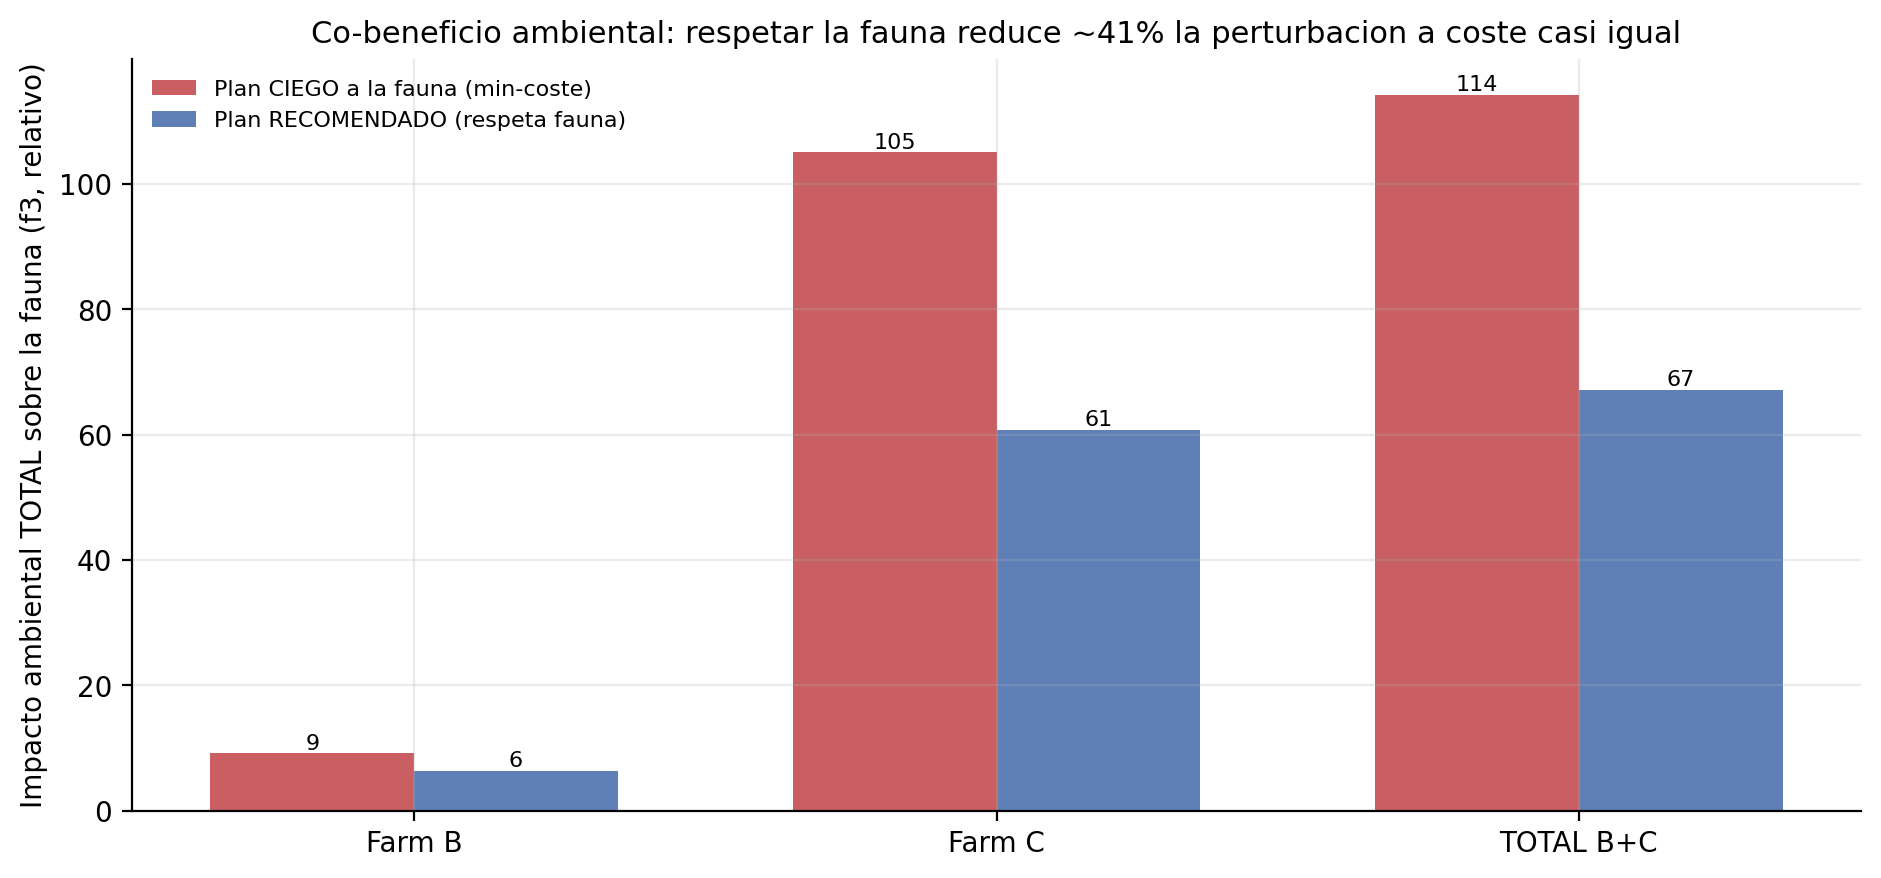

Farm B   : impacto recomendado      6 vs ciego      9  -> -31% de molestia
Farm C   : impacto recomendado     61 vs ciego    105  -> -42% de molestia
TOTAL B+C: impacto recomendado     67 vs ciego    114  -> -41% de molestia


In [12]:
grupos, keys = ["Farm B", "Farm C", "TOTAL B+C"], ["B", "C", "Total"]
imp_ciego = [AGG[k]["imp_ciego"] for k in keys]
imp_rec = [AGG[k]["imp_rec"] for k in keys]
x = np.arange(len(grupos)); w = 0.35
fig, ax = plt.subplots(figsize=(9.5, 4.5))
b1 = ax.bar(x - w / 2, imp_ciego, w, label="Plan CIEGO a la fauna (min-coste)", color="#C44E52", alpha=0.9)
b2 = ax.bar(x + w / 2, imp_rec, w, label="Plan RECOMENDADO (respeta fauna)", color="#4C72B0", alpha=0.9)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.0f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x); ax.set_xticklabels(grupos)
ax.set_ylabel("Impacto ambiental TOTAL sobre la fauna (f3, relativo)")
ax.set_title("Co-beneficio ambiental: respetar la fauna reduce ~41% la perturbacion a coste casi igual")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

for k in ["B", "C", "Total"]:
    a = AGG[k]; et = f"Farm {k}" if k != "Total" else "TOTAL B+C"
    red = 100 * (a["imp_ciego"] - a["imp_rec"]) / a["imp_ciego"] if a["imp_ciego"] else 0
    print(f"{et:9s}: impacto recomendado {a['imp_rec']:6.0f} vs ciego {a['imp_ciego']:6.0f}  -> -{red:.0f}% de molestia")

## 5b. El ahorro neto, descontando las falsas alarmas

El ahorro anterior cuenta los fallos reales escalados. Pero un sistema predictivo no es gratis,
porque si la categorización escala una **falsa alarma**, es decir, un periodo normal, se ejecuta un
plan para nada. El balance lo descuenta **en el mismo marco esperado del apartado 5**:

> ahorro neto = Σ (anomalías escaladas: reactivo − plan recomendado) − Σ (falsas escaladas: coste
> esperado del plan recomendado, ejecutado en vano)

Se reutiliza la **misma categorización** del apartado 5 sobre todos los eventos del parque B (15) y
del parque C (58). Las etiquetas reales se usan **solo** para clasificar acierto o falsa alarma,
nunca en el diagnóstico.

El coste de la falsa alarma es una **cota conservadora**, porque se contabiliza el plan recomendado
completo, con la potencia limitada mientras espera, la intervención y su término de riesgo residual,
que en una turbina sana no llegaría a materializarse. En la práctica, una inspección abortaría el
plan antes de movilizar el barco.

In [13]:
_bruto = _neto_tot = 0.0
for _f in ["B", "C"]:
    _esc = [d for d in TRIAJE[_f] if d["action"] is TriageAction.ESCALAR]
    _tp = [d for d in _esc if d["label"] == "anomaly"]   # aciertos (fallos reales)
    _fp = [d for d in _esc if d["label"] != "anomaly"]   # falsas alarmas (normales escalados)
    _ah = AGG[_f]["reactivo"] - AGG[_f]["recomendado"]   # bruto
    _cf = sum(_plan_rec(d["sub"], d["mes"], True)[1].objetivos.coste_esperado for d in _fp)
    _net = _ah - _cf
    print(f"Farm {_f}, {len(TRIAJE[_f])} eventos | ESCALAR: {len(_tp)} aciertos + {len(_fp)} falsas alarmas")
    print(f"  (+) ahorro del plan {_ah:>13,.0f}   (-) falsas {_cf:>12,.0f}   (=) NETO {_net:>13,.0f}  "
          f"({100 * _net / _ah if _ah else 0:.0f}% del bruto)")
    _bruto += _ah; _neto_tot += _net
print()
print(f"TOTAL B+C: ahorro NETO {_neto_tot:,.0f} de {_bruto:,.0f} bruto ({100 * _neto_tot / _bruto:.0f}%)")

Farm B, 15 eventos | ESCALAR: 4 aciertos + 1 falsas alarmas
  (+) ahorro del plan     1,507,584   (-) falsas      263,480   (=) NETO     1,244,104  (83% del bruto)


Farm C, 58 eventos | ESCALAR: 17 aciertos + 2 falsas alarmas
  (+) ahorro del plan     7,197,767   (-) falsas    1,849,021   (=) NETO     5,348,747  (74% del bruto)

TOTAL B+C: ahorro NETO 6,592,851 de 8,705,352 bruto (76%)


## 6. Conclusiones y limitaciones

1. **La tensión del sistema es real y está medida.** ERA5 (2014-2023) confirma que junio es el mes
   más accesible, con un 10 % inaccesible, y que coincide con la reproducción de la marsopa. El
   conflicto entre meteorología y fauna no es un supuesto, y es robusto a los pesos de la base de
   conocimiento, porque lo conduce el calendario de solapamiento de especies y no los números
   exactos.
2. **La planificación multiobjetivo produce decisiones, no una respuesta.** El frente de Pareto
   entrega al operador el abanico de compromisos entre coste, riesgo y fauna. El *knee* sugiere uno,
   pero la ponderación es una **decisión de política**, no del modelo. NSGA-II domina al `greedy` y
   toca el óptimo exacto verificable.
3. **El análisis estacional hace tangible el valor de anticiparse.** La misma alarma cuesta muy
   distinto en junio, con el *jack-up* vetado por la marsopa y la reparación diferida, que en
   octubre. Detectar con antelación permite **elegir** la ventana en lugar de aceptar la que toque.
4. **Optimizar la espera, y no solo la reparación, expande la frontera.** La híbrida optimizada
   convierte el día de parada en una variable de decisión más, acotada por el umbral de seguridad,
   de modo que el límite de seguridad se conserva. Frente a la híbrida de umbral fijo del apartado 4
   no la domina, sino que **reordena el compromiso**, alcanzando estados de riesgo e impacto mucho
   menores, porque parar antes en las ventanas sensibles corta riesgo y ruido a la vez, a costa de
   más producción perdida. Es una palanca ambiental eficaz, pero su *knee* se desplaza a una zona
   cara, y por eso la recomendación económica por defecto sigue siendo el *knee* de la híbrida fija.
5. **El mantenimiento predictivo ahorra en los dos parques, incluso cuidando la fauna y descontando
   las falsas alarmas.** Agregando por parque sobre **todos** los fallos detectados con su mes real
   (apartado 5), y recomendando el mejor plan entre todas las políticas de espera
   (`recomendar_union`, la misma que usa la consola), el plan recomendado ahorra el **40 %** de la
   factura reactiva (**51 %** en B, **39 %** en C, y **29 %** en lectura de flota). Ignorando la
   fauna se llegaría al **56 %**, y esa diferencia, **el 28 % del ahorro ciego**, es **lo que cuesta
   proteger la fauna**, concentrada en los fallos de verano que exigen *jack-up*. Ese sobrecoste
   compra el co-beneficio ambiental del apartado 5a, **un 41 % menos de perturbación** (67 frente a
   114) por un ahorro casi igual. Y descontando las falsas alarmas en el mismo marco (apartado 5b),
   el ahorro neto conserva el **76 %**, porque evitar un solo fallo catastrófico vale mucho más que
   unas pocas intervenciones de más. Es la justificación económica del sistema completo, detectar
   (notebooks 1 a 4), diagnosticar (5) y planificar (6).

**Limitaciones.** Los costes son **relativos**, porque el conjunto de datos está anonimizado, y
valen el orden y el porcentaje, no el valor absoluto. Los parámetros del catálogo de tareas y los
pesos de sensibilidad llevan su fuente o están marcados como supuesto, con Carroll 2015 para el
orden de criticidad de la multiplicadora y los pesos de fauna como elección de modelado, con su
análisis de sensibilidad. La inaccesibilidad anual absoluta de ERA5, un 29 %, depende del umbral y
del punto, porque el German Bight está abrigado, y lo robusto es la **estacionalidad**. El
subsistema no se identifica desde canales anonimizados, se asigna de forma representativa. Y el veto
de reproducción es una política configurable, no una obligación legal universal.

El modelo de coste lleva sus propios supuestos, todos marcados en el catálogo. La máquina degradada
opera con **potencia limitada**, en torno a un 20 % de pérdida, el *"at most 20 % of rated power"*
de la literatura, lo que frena el fallo y **aleja** la rotura a aproximadamente el doble de la
urgencia estimada, con la ventana anclada a la norma ISO 281, según la cual reducir la carga un 20 %
duplica la vida del rodamiento, con L10 ~ (C/P)^(10/3). Limitar la potencia **no evita** el fallo,
solo lo pospone, porque el riesgo crece de forma **convexa**, bajo mientras hay margen y empinado
cerca de la rotura, hasta **1.0** en esa fecha extendida, de modo que diferir de más significa
perder la turbina. Actuar antes del plazo de contratación del buque acarrea una prima de urgencia.

Se modelan cuatro políticas de espera. **Limitar potencia** a secas, en la que si se difiere más
allá de la fecha de rotura el riesgo llega a 1.0 y se pierde la turbina. **Parar** desde el primer
día, con riesgo próximo a cero a costa de toda la producción. La **híbrida** de referencia, que
limita y para al alcanzar el umbral de riesgo fijo `RIESGO_STOP` = 0.40, que **congela** el riesgo y
evita que llegue a 1.0. Y la **híbrida optimizada**, en la que el día de parada es una variable de
decisión acotada por ese mismo umbral. El umbral acota el riesgo en las dos híbridas, y la
optimizada además optimiza dentro de esa cota. `RIESGO_STOP` y `RIESGO_EXP` son supuestos de
modelado y quedan listados aquí.